In [1]:
from pathlib import Path
import pandas as pd

csv = Path("../results/runs/tournament_20250919_183650/results.csv") # último resultados.csv
csv

WindowsPath('../results/runs/tournament_20250919_183650/results.csv')

In [2]:
df = pd.read_csv(csv)
df.head()

,A,B,pa,pb,seed
0,AlwaysSplit,AlwaysSteal,6,138,1826701614
1,AlwaysSplit,AlwaysSteal,2,134,1367864806
2,AlwaysSplit,AlwaysSteal,2,140,1097657231
3,AlwaysSplit,AlwaysSteal,2,146,579362555
4,AlwaysSplit,AlwaysSteal,8,140,661058651


In [3]:
A = df[["A","pa","pb"]].rename(columns={"A":"name","pa":"score","pb":"opp"})
B = df[["B","pb","pa"]].rename(columns={"B":"name","pb":"score","pa":"opp"})
u = pd.concat([A,B], ignore_index=True)

summary = (u.assign(win=(u.score>u.opp), loss=(u.score<u.opp), tie=(u.score==u.opp))
             .groupby("name", as_index=False)
             .agg(matches=("score","size"),
                  wins=("win","sum"),
                  losses=("loss","sum"),
                  ties=("tie","sum"),
                  mean_payoff=("score","mean"),
                  median_payoff=("score","median"))
             .sort_values(["mean_payoff","wins"], ascending=[False,False]))
summary


,name,matches,wins,losses,ties,mean_payoff,median_payoff
1,AlwaysSplit,180000,9002,159890,11108,67.994533,87.0
5,MimicMajority,180000,43051,119012,17937,67.561222,83.0
3,GenTFT_e0.1,180000,40603,118771,20626,61.129872,69.0
9,WSLS,180000,62347,85705,31948,60.025267,69.0
7,TitForTat,180000,62697,85640,31663,59.980222,69.0
0,Alternator,180000,74480,91018,14502,56.096811,69.0
6,RandomP50,180000,74715,91632,13653,54.453144,60.0
4,GrimTrigger,180000,144637,21253,14110,53.347072,46.0
8,TwoTitsForTat,180000,143290,22192,14518,53.327889,53.0
2,AlwaysSteal,180000,154583,14292,11125,42.354717,20.0


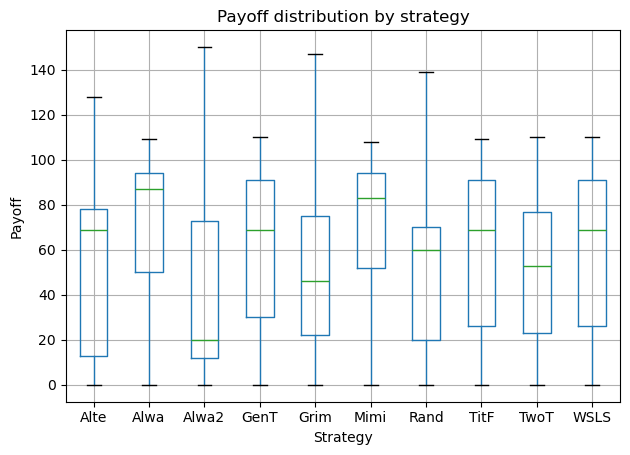

In [ ]:
"""
import matplotlib.pyplot as plt

u.boxplot(column="score", by="name", grid=True, rot=0)
plt.title("Payoff distribution by strategy")
plt.suptitle("")  # quita el subtítulo automático
plt.xlabel("Strategy"); plt.ylabel("Payoff")
plt.show()
"""

import matplotlib.pyplot as plt

ax = u.boxplot(column="score", by="name", grid=True, rot=0)
plt.title("Payoff distribution by strategy")
plt.suptitle("")
plt.xlabel("Strategy"); plt.ylabel("Payoff")

# --- etiquetas cortas (4 chars) ---
from collections import defaultdict
seen = defaultdict(int)
short_labels = []
for tick in ax.get_xticklabels():
    s = tick.get_text()[:4]
    seen[s] += 1
    # si hay colisiones (dos nombres con mismos 4 chars), añade sufijo 2,3,...
    short_labels.append(s if seen[s] == 1 else f"{s}{seen[s]}")

ax.set_xticklabels(short_labels, rotation=0)
plt.tight_layout()
plt.show()



WindowsPath('../results/figs/payoff_boxplot.png')

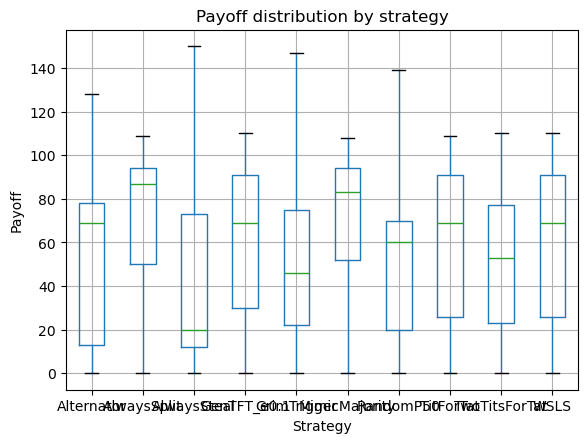

In [9]:
fig_path = Path("../results") / "figs"
fig_path.mkdir(parents=True, exist_ok=True)

ax = u.boxplot(column="score", by="name", grid=True, rot=0)
plt.title("Payoff distribution by strategy"); plt.suptitle("")
plt.xlabel("Strategy"); plt.ylabel("Payoff")
out = fig_path / "payoff_boxplot.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
out
